# P2-f2 — HAR-YZ walk-forward: train (2021–2023) and test (2024 → 2026 Q3)

Question: how well does HAR-YZ "train", and does the refit schedule matter?

| Period | Role |
|---|---|
| 2019 → 2020 | Initial fit (targets dated 2019-02 → 2020-12) |
| 2021 → 2023 | Walk-forward: forecast each day, refit on schedule, score RMSE + QLIKE |
| 2024-01-01 → 2026-09-30 | Test: **annual walk-forward only** (the P2-f2 convention), scored once |

- Inputs: `yz_var_daily` (from `yz.py`) and its 5- and 22-day averages.
- Target (left side of the regression and the scoring target): `r2_next`, the next day's squared close-to-close return. **Provisional** (not decided yet).
- HAR fitted in variance levels by OLS, expanding window from 2019.
- Refit schemes: `static` (fit once on 2019–20, never refit), `annual`, `monthly`, `daily`.
- Benchmark (naive): carry forward `yz_var_22`, the latest 22-bar YZ.
- Timing: the forecast for day t+1 is made at the close of day t, using only rows whose target day ≤ t.
- Units: variance of % returns (log-return variance × 1e4).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

YZ = Path('yz_data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
EVAL = (pd.Timestamp('2021-01-01', tz='UTC'), pd.Timestamp('2024-01-01', tz='UTC'))  # train, target dates [start, end)
TEST = (pd.Timestamp('2024-01-01', tz='UTC'), pd.Timestamp('2026-10-01', tz='UTC'))  # test, target dates [start, end)
SCHEMES = ['static', 'annual', 'monthly', 'daily']
X_COLS = ['rv_d', 'rv_w', 'rv_m']
SCALE = 1e4  # log-return variance -> %^2

# reference categorical palette, fixed order
C = {'realized': '#b4b2ab', 'naive': '#eb6834', 'HAR daily': '#2a78d6',
     'bd': '#2a78d6', 'bw': '#eb6834', 'bm': '#1baf7a'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'lines.linewidth': 1.2, 'figure.dpi': 110})

In [2]:
def load(sym):
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    d[['yz_var_daily', 'yz_var_22', 'r2_next']] *= SCALE
    d['rv_d'] = d.yz_var_daily
    d['rv_w'] = d.yz_var_daily.rolling(5).mean()
    d['rv_m'] = d.yz_var_daily.rolling(22).mean()
    d['target_date'] = d.index.to_series().shift(-1)
    return d.dropna(subset=['rv_m', 'yz_var_22', 'r2_next'])

data = {s: load(s) for s in ASSETS}
{s: (d.index[0].date(), d.index[-1].date(), len(d)) for s, d in data.items()}

{'BTC': (datetime.date(2019, 1, 23), datetime.date(2026, 10, 28), 2836),
 'ETH': (datetime.date(2019, 1, 23), datetime.date(2026, 10, 28), 2836),
 'QQQ': (datetime.date(2019, 2, 4), datetime.date(2026, 10, 28), 1945),
 'XAUUSD': (datetime.date(2019, 2, 1), datetime.date(2026, 10, 28), 1998)}

## Walk-forward

Row j holds the inputs of day j and the target of day j+1. At origin row i (the close of day i), rows j < i have known targets, so every fit uses `d.iloc[:i]`.
A refit happens at the first origin of each group (year / month / day of the target date). `static` uses the single fit made at the first 2021 origin, i.e. targets 2019 → 2020-12-31.

In [3]:
def ols(df):
    X = np.column_stack([np.ones(len(df)), df[X_COLS].to_numpy()])
    return np.linalg.lstsq(X, df.r2_next.to_numpy(), rcond=None)[0]

def group_keys(tgt, scheme):
    return {'static': np.zeros(len(tgt), int),
            'annual': tgt.year.to_numpy(),
            'monthly': (tgt.year * 100 + tgt.month).to_numpy(),
            'daily': np.arange(len(tgt))}[scheme]

def walk_forward(d, scheme, ev=EVAL):
    pos = np.flatnonzero((d.target_date >= ev[0]) & (d.target_date < ev[1]))
    keys = group_keys(pd.DatetimeIndex(d.target_date.iloc[pos]), scheme)
    fc, betas = np.empty(len(pos)), []
    for k in pd.unique(keys):
        m = keys == k
        b = ols(d.iloc[:pos[m][0]])
        betas.append((d.index[pos[m][0]], *b))
        rows = d.iloc[pos[m]]
        fc[m] = np.column_stack([np.ones(m.sum()), rows[X_COLS].to_numpy()]) @ b
    idx = d.index[pos]
    return pd.Series(fc, idx), pd.DataFrame(betas, columns=['origin', 'b0', 'bd', 'bw', 'bm']).set_index('origin')

fc, betas = {}, {}
for s, d in data.items():
    fc[s] = pd.DataFrame({'naive': d.yz_var_22})
    for sch in SCHEMES:
        f, b = walk_forward(d, sch)
        fc[s][f'HAR {sch}'] = f
        betas[s, sch] = b
    fc[s] = fc[s].loc[f.index]
    fc[s]['realized'] = d.r2_next.loc[f.index]

## Initial fit (2019 → 2020) — coefficients and in-sample R²

In [4]:
rows = []
for s, d in data.items():
    fit = d[d.target_date < EVAL[0]]
    b = ols(fit)
    pred = np.column_stack([np.ones(len(fit)), fit[X_COLS].to_numpy()]) @ b
    r2 = 1 - np.sum((fit.r2_next - pred)**2) / np.sum((fit.r2_next - fit.r2_next.mean())**2)
    rows.append([s, len(fit), *b, b[1:].sum(), r2])
pd.DataFrame(rows, columns=['asset', 'n', 'b0', 'bd', 'bw', 'bm', 'bd+bw+bm', 'R2']).set_index('asset').round(3)

,n,b0,bd,bw,bm,bd+bw+bm,R2
asset,,,,,,,
BTC,708,12.198,0.141,-0.005,0.088,0.224,0.006
ETH,708,16.406,0.259,0.006,0.067,0.332,0.013
QQQ,482,0.708,0.692,-0.124,0.246,0.815,0.210
XAUUSD,494,0.384,-0.074,0.450,0.181,0.557,0.095


## Out-of-sample scores, 2021–2023

QLIKE = mean(ln h + RV/h), which needs h > 0. For each asset, models are scored on the **same dates**: any date where some forecast is ≤ 0 is dropped for every model and counted in `dropped`.
`RMSE/naive` < 1 and `ΔQLIKE` < 0 mean better than naive.

In [5]:
def score(f):
    models = [c for c in f.columns if c != 'realized']
    ok = (f[models] > 0).all(axis=1)
    g, rv = f[ok], f.realized[ok]
    out = pd.DataFrame({m: {'RMSE': np.sqrt(np.mean((g[m] - rv)**2)),
                            'QLIKE': np.mean(np.log(g[m]) + rv / g[m]),
                            'nonpos': int((f[m] <= 0).sum())} for m in models}).T
    out['RMSE/naive'] = out.RMSE / out.loc['naive', 'RMSE']
    out['ΔQLIKE'] = out.QLIKE - out.loc['naive', 'QLIKE']
    out['dropped'] = int((~ok).sum())
    out['n'] = int(ok.sum())
    return out

scores = pd.concat({s: score(f) for s, f in fc.items()})
scores.round(3)

RMSE  QLIKE  nonpos  RMSE/naive  ΔQLIKE  dropped     n
BTC    naive        28.457  3.428     0.0       1.000   0.000        0  1095
       HAR static   26.695  3.420     0.0       0.938  -0.009        0  1095
       HAR annual   26.588  3.401     0.0       0.934  -0.027        0  1095
       HAR monthly  26.506  3.386     0.0       0.931  -0.042        0  1095
       HAR daily    26.510  3.385     0.0       0.932  -0.044        0  1095
ETH    naive        56.003  3.791     0.0       1.000   0.000        0  1095
       HAR static   52.771  3.865     0.0       0.942   0.074        0  1095
       HAR annual   52.831  3.855     0.0       0.943   0.063        0  1095
       HAR monthly  52.646  3.835     0.0       0.940   0.043        0  1095
       HAR daily    52.693  3.831     0.0       0.941   0.039        0  1095
QQQ    naive         4.066  1.634     0.0       1.000   0.000        0   753
       HAR static    4.241  1.674     0.0       1.043   0.040        0   753
       HAR annual    4.232  1.678     0.0       1.041   0.044        0   753
       HAR monthly   4.194  1.660     0.0       1.031   0.026        0   753
       HAR daily     4.193  1.660     0.0       1.031   0.026        0   753
XAUUSD naive         1.395  0.734     0.0       1.000   0.000        0   773
       HAR static    1.380  0.694     0.0       0.989  -0.040        0   773
       HAR annual    1.379  0.694     0.0       0.989  -0.041        0   773
       HAR monthly   1.380  0.694     0.0       0.989  -0.040        0   773
       HAR daily     1.380  0.694     0.0       0.989  -0.041        0   773

In [6]:
# QLIKE and RMSE per calendar year (stability across regimes)
yr = pd.concat({(s, y): score(f[f.index.year == y])[['RMSE/naive', 'ΔQLIKE']]
                for s, f in fc.items() for y in (2020, 2021, 2022, 2023)
                if (f.index.year == y).sum() > 30})
yr.unstack(level=1).round(3)

RMSE/naive               ΔQLIKE              
                         2021   2022   2023   2021   2022   2023
BTC    naive            1.000  1.000  1.000  0.000  0.000  0.000
       HAR static       0.885  0.972  1.177 -0.088 -0.083  0.145
       HAR annual       0.885  0.972  1.126 -0.088 -0.084  0.091
       HAR monthly      0.885  0.971  1.092 -0.085 -0.091  0.048
       HAR daily        0.886  0.971  1.089 -0.083 -0.093  0.044
ETH    naive            1.000  1.000  1.000  0.000  0.000  0.000
       HAR static       0.933  0.928  1.425 -0.074 -0.086  0.381
       HAR annual       0.933  0.938  1.370 -0.074 -0.086  0.350
       HAR monthly      0.932  0.938  1.281 -0.063 -0.088  0.281
       HAR daily        0.933  0.938  1.275 -0.067 -0.089  0.276
QQQ    naive            1.000  1.000  1.000  0.000  0.000  0.000
       HAR static       0.962  1.055  1.066 -0.022  0.093  0.053
       HAR annual       0.962  1.054  1.048 -0.023  0.107  0.050
       HAR monthly      0.959  1.043  1.040 -0.030  0.074  0.037
       HAR daily        0.959  1.043  1.039 -0.031  0.073  0.036
XAUUSD naive            1.000  1.000  1.000  0.000  0.000  0.000
       HAR static       0.988  0.987  0.991 -0.043 -0.019 -0.061
       HAR annual       0.988  0.988  0.989 -0.042 -0.018 -0.065
       HAR monthly      0.988  0.988  0.990 -0.044 -0.018 -0.062
       HAR daily        0.988  0.989  0.990 -0.044 -0.018 -0.063

## Forecast vs realized (daily volatility, %, log scale)

√(forecast variance) vs |next-day return|. Grey = realized, blue = HAR (daily refit), orange = naive.

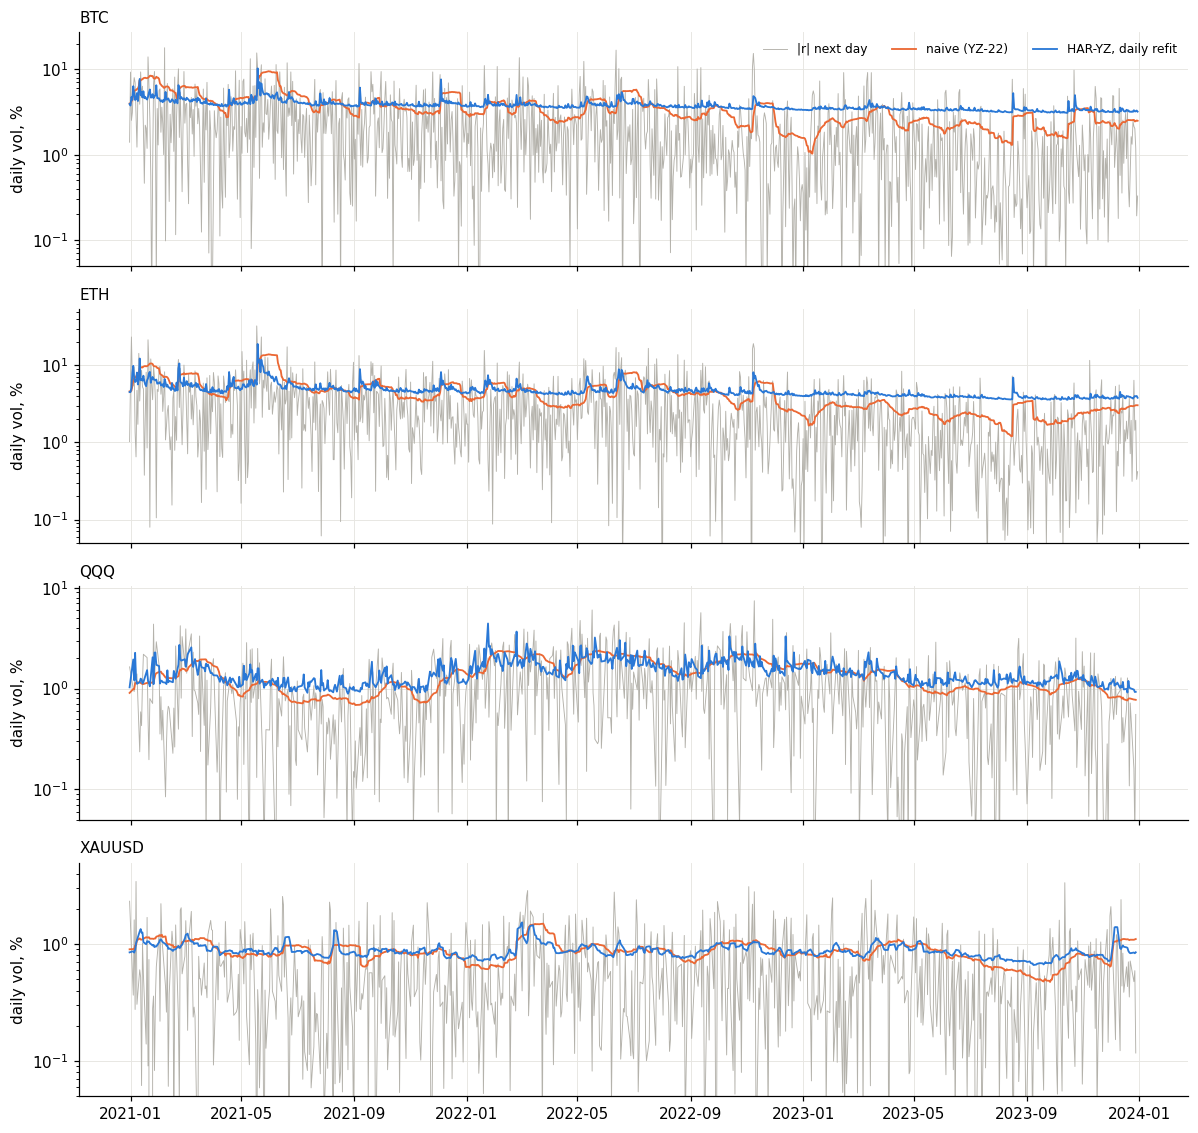

In [7]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    f = fc[s]
    ax.plot(f.index, np.sqrt(f.realized), color=C['realized'], lw=0.6, label='|r| next day')
    ax.plot(f.index, np.sqrt(f['naive'].clip(lower=0)), color=C['naive'], lw=1.2, label='naive (YZ-22)')
    ax.plot(f.index, np.sqrt(f['HAR daily'].clip(lower=1e-6)), color=C['HAR daily'], lw=1.2, label='HAR-YZ, daily refit')
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=3, frameon=False, fontsize=8)
fig.tight_layout()

## Coefficient paths (daily refit, expanding window)

How much the weights move as data accumulates. β₀ is left out (different scale).

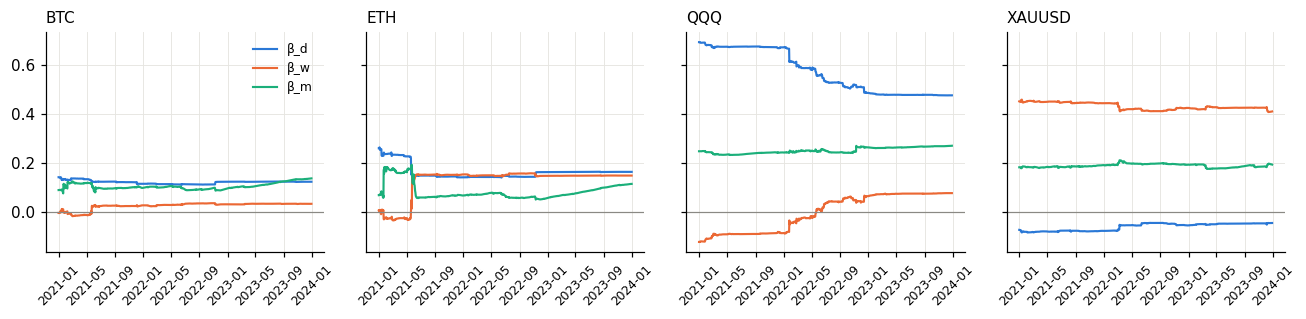

In [8]:
fig, axes = plt.subplots(1, len(ASSETS), figsize=(12, 3), sharey=True)
for ax, s in zip(axes, ASSETS):
    b = betas[s, 'daily']
    for k, lab in [('bd', 'β_d'), ('bw', 'β_w'), ('bm', 'β_m')]:
        ax.plot(b.index, b[k], color=C[k], lw=1.4, label=lab)
    ax.axhline(0, color='#8a8984', lw=0.8)
    ax.set_title(s, loc='left', fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## Findings on train (2021–2023, provisional target r²; run 2026-11-01)

| Asset | RMSE vs naive | ΔQLIKE vs naive | Verdict on train |
|---|---:|---:|---|
| BTC | −7% | −0.04 | Better, except 2023 |
| ETH | −6% | **+0.04** | Mixed: RMSE better, QLIKE worse (2023) |
| QQQ | **+3%** | **+0.03** | Worse than naive (2022–23) |
| XAUUSD | −1% | −0.04 | Slightly better every year |

(Daily refit; the other schemes are within a few % of it.)

- **For crypto, HAR fitted to r² in levels is close to a flat line.** On 2019–20 the three weights sum to only 0.22 (BTC) and 0.33 (ETH), in-sample R² ≈ 0.01, and the intercept carries the forecast. That is why it beats naive in high-vol 2021–22 and loses in calm 2023: it keeps forecasting the old average. Likely cause: OLS on a noisy, spike-dominated target (single-day r²) shrinks the slopes. QQQ has the most persistence (weights sum 0.82, R² 0.21), but there it still loses to naive.
- **The refit schedule matters only when the regime moves.** Daily ≈ monthly everywhere. Static/annual are worse only in 2023 for crypto (BTC ΔQLIKE +0.145 static vs +0.044 daily), where the 2019–20 fit was most out of date. Gold is identical across schemes.
- **No non-positive forecasts** in levels on any asset, so the levels-vs-log question is not forced by QLIKE here. Log-HAR may still help the slope-shrinking problem above (untested).
- Not tested: significance of the differences. The target is still provisional; re-run once it is decided.

# Test: 2024-01-01 → 2026-09-30 (annual walk-forward)

Fold Y = targets dated in calendar year Y. β is fitted once at the first origin of fold Y on every row with target ≤ 31 Dec of Y−1 (expanding from 2019) and held fixed through Y.
Folds: 2024 (fit 2019–2023), 2025 (fit 2019–2024), 2026 Jan–Sep (fit 2019–2025). Only the annual scheme is scored, so the test is not used to choose a refit schedule.

In [9]:
fc_test, betas_test = {}, {}
for s, d in data.items():
    f, b = walk_forward(d, 'annual', TEST)
    fc_test[s] = pd.DataFrame({'naive': d.yz_var_22.loc[f.index], 'HAR annual': f,
                               'realized': d.r2_next.loc[f.index]})
    betas_test[s] = b.assign(sum_w=b[['bd', 'bw', 'bm']].sum(axis=1))
pd.concat(betas_test).round(3)

b0     bd     bw     bm  sum_w
       origin                                                       
BTC    2023-12-31 00:00:00+00:00   8.810  0.122  0.032  0.136  0.290
       2024-12-31 00:00:00+00:00   7.974  0.120  0.037  0.148  0.305
       2025-12-31 00:00:00+00:00   6.959  0.119  0.042  0.166  0.327
ETH    2023-12-31 00:00:00+00:00  11.549  0.162  0.147  0.114  0.423
       2024-12-31 00:00:00+00:00  10.297  0.158  0.151  0.127  0.435
       2025-12-31 00:00:00+00:00  10.274  0.140  0.152  0.121  0.413
QQQ    2023-12-29 00:00:00+00:00   0.608  0.475  0.076  0.269  0.820
       2024-12-31 00:00:00+00:00   0.561  0.444  0.106  0.272  0.821
       2025-12-31 00:00:00+00:00   0.522  0.451  0.258  0.136  0.845
XAUUSD 2023-12-29 00:00:00+00:00   0.347 -0.046  0.409  0.191  0.555
       2024-12-31 00:00:00+00:00   0.378 -0.044  0.401  0.185  0.542
       2025-12-31 00:00:00+00:00   0.383 -0.022  0.430  0.187  0.594

In [10]:
scores_test = pd.concat({s: score(f) for s, f in fc_test.items()})
scores_test.round(3)

RMSE  QLIKE  nonpos  RMSE/naive  ΔQLIKE  dropped     n
BTC    naive       14.369  2.818     0.0       1.000   0.000        0  1004
       HAR annual  14.595  2.876     0.0       1.016   0.058        0  1004
ETH    naive       31.516  3.631     0.0       1.000   0.000        0  1004
       HAR annual  30.857  3.534     0.0       0.979  -0.098        0  1004
QQQ    naive        6.887  1.477     0.0       1.000   0.000        0   689
       HAR annual   6.457  1.377     0.0       0.937  -0.100        0   689
XAUUSD naive        4.766  1.459     0.0       1.000   0.000        0   710
       HAR annual   4.509  1.413     0.0       0.946  -0.047        0   710

In [11]:
yr_test = pd.concat({(s, y): score(f[f.index.year == y])[['RMSE/naive', 'ΔQLIKE']]
                     for s, f in fc_test.items() for y in (2023, 2024, 2025, 2026)
                     if (f.index.year == y).sum() > 30})
yr_test.unstack(level=1).round(3)

RMSE/naive               ΔQLIKE              
                        2024   2025   2026   2024   2025   2026
BTC    naive           1.000  1.000  1.000  0.000  0.000  0.000
       HAR annual      1.015  1.070  0.992  0.035  0.142 -0.020
ETH    naive           1.000  1.000  1.000  0.000  0.000  0.000
       HAR annual      1.007  0.964  0.982  0.017 -0.164 -0.163
QQQ    naive           1.000  1.000  1.000  0.000  0.000  0.000
       HAR annual      1.022  0.931  0.984 -0.053 -0.153 -0.086
XAUUSD naive           1.000  1.000  1.000  0.000  0.000  0.000
       HAR annual      0.990  0.985  0.937 -0.050 -0.064 -0.018

Test forecasts vs realized (daily volatility, %, log scale). Grey = |next-day return|, blue = HAR (annual refit), orange = naive.

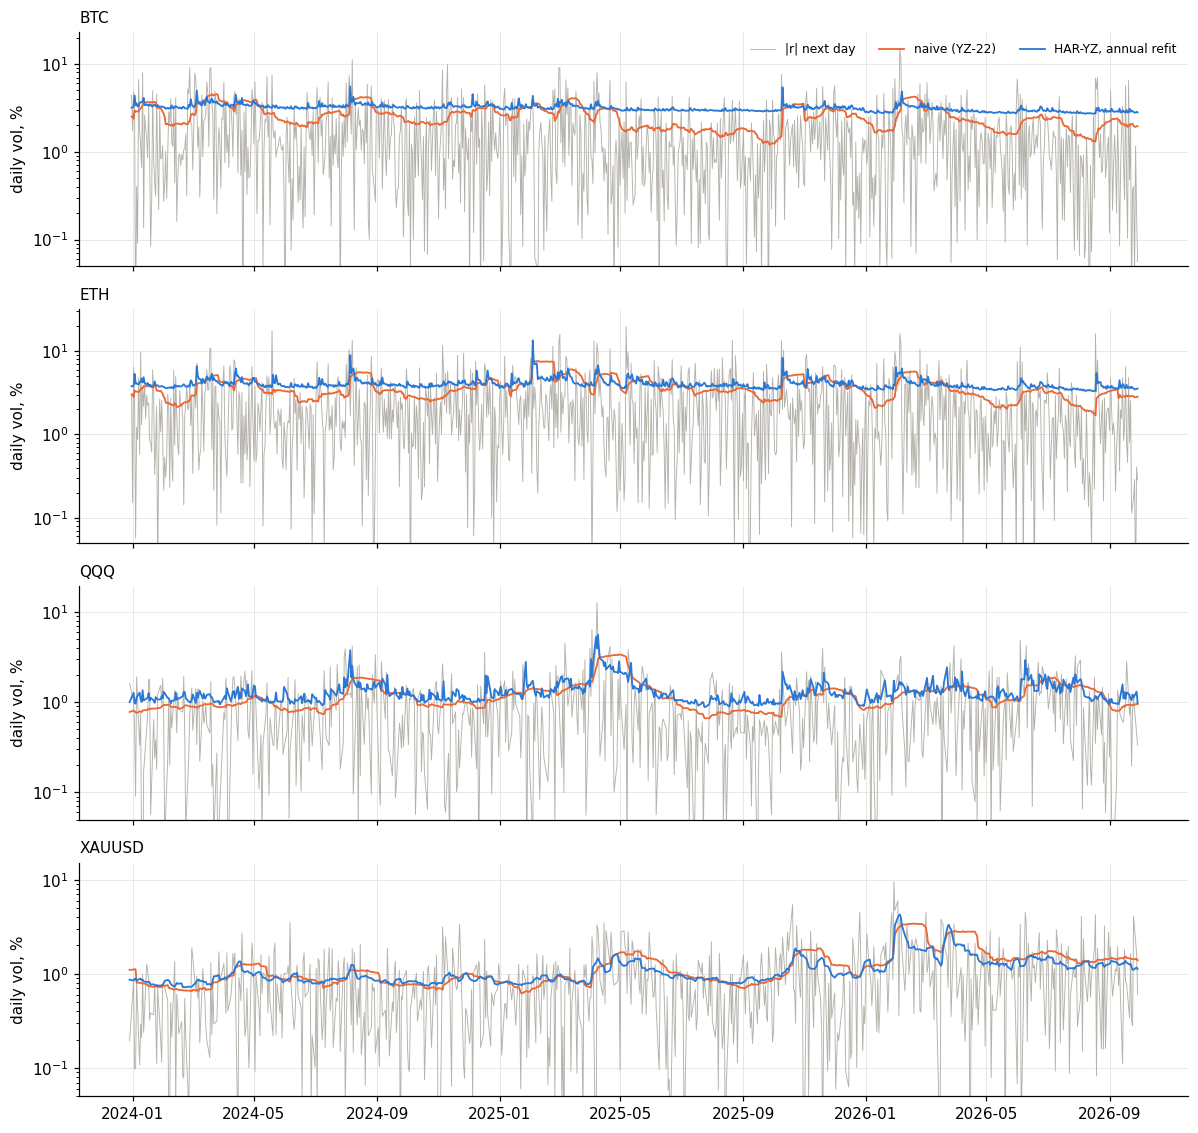

In [12]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    f = fc_test[s]
    ax.plot(f.index, np.sqrt(f.realized), color=C['realized'], lw=0.6, label='|r| next day')
    ax.plot(f.index, np.sqrt(f['naive'].clip(lower=0)), color=C['naive'], lw=1.2, label='naive (YZ-22)')
    ax.plot(f.index, np.sqrt(f['HAR annual'].clip(lower=1e-6)), color=C['HAR daily'], lw=1.2, label='HAR-YZ, annual refit')
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=3, frameon=False, fontsize=8)
fig.tight_layout()

## Findings on test (2024-01-01 → 2026-09-30, annual walk-forward; run 2026-11-01)

| Asset | RMSE vs naive | ΔQLIKE vs naive | Train verdict | Test verdict |
|---|---:|---:|---|---|
| BTC | +2% | **+0.06** | Better | **Worse** (2024–25) |
| ETH | −2% | −0.10 | Mixed | Better (2025–26) |
| QQQ | −6% | −0.10 | **Worse** | **Better** every year |
| XAUUSD | −5% | −0.05 | Slightly better | Better every year |

- **Gold is the only asset where HAR beats naive consistently,** on train and in every test year.
- **The ranking flips between train and test for BTC and QQQ.** HAR's edge over naive is not stable across regimes for those two, which is weak evidence either way. Significance is not tested yet (Diebold–Mariano pending).
- **Coefficients barely move from fold to fold** (e.g. BTC weights sum 0.29 → 0.33). With an expanding window from 2019, each annual refit adds one year to 5+ years of history. Crypto HAR is still mostly intercept (weights sum ≤ 0.44), so it stays close to a long-run average.
- No non-positive forecasts. Target still provisional.

## Save forecasts → `forecasts/<SYM>-HAR-YZ.csv`

Annual walk-forward forecasts for train (2021–23) and test (2024 → 2026-09-30), for the cross-model comparison. Index = forecast origin (the close of day t); `target_date` = day t+1; `h` = forecast variance in %².

In [13]:
FC = Path('forecasts'); FC.mkdir(exist_ok=True)
for s, d in data.items():
    tr = fc[s]['HAR annual'].rename('h').to_frame().assign(split='train')
    te = fc_test[s]['HAR annual'].rename('h').to_frame().assign(split='test')
    out = pd.concat([tr, te])
    out.insert(0, 'target_date', d.target_date.loc[out.index])
    out['fold'] = pd.DatetimeIndex(out.target_date).year
    assert out.index.is_unique
    out.to_csv(FC / f'{s}-HAR-YZ.csv')
{s: len(pd.read_csv(FC / f'{s}-HAR-YZ.csv')) for s in ASSETS}

{'BTC': 2099, 'ETH': 2099, 'QQQ': 1442, 'XAUUSD': 1483}